# On new Pile rows, does the adversarial check fail SGD's teacher-trained decomposition?

*E49, row blocks, 2026-10-29. Report: `reports/analyses/2026-10-29_analysis_e49-row-blocks.md`.*

## The answer

Adam's teacher-trained decomposition fails every new block of text and the LoRA's passes every one, as expected. Both
SGD ones pass every new block too, but that pass means almost nothing. The plain SGD fine-tune left whole in Δ, which
the check ought to fail, also passes every block. So on ordinary text this check cannot see SGD's update at all. The
old SGD fail on one hard block did not repeat at two more adversary starts for plain SGD, though the filed rule calls
that block "mixed".

## What we were trying to test

The question behind `GOALS.md`'s weak version is whether teacher training can keep the decomposition faithful along a
broad update. *Teacher training* trains the alive subcomponents of the released decomposition to imitate a fine-tuned
model, with Γ and Δ frozen; the result is the fine-tune's *teacher-trained decomposition*. E39 did this for four
fine-tunes on a broad lowercase task: Adam, plain SGD, SGD held to rank 8 in every matrix, and a rank-8 LoRA.

**The check.** The paper's adversarial check runs a 20-step adversary over the masks from one random start. Here it is
read on one *block* of 128 Pile rows at a time. The *block ratio* is a state's KL under the adversary over the unchanged
decomposition W₀'s KL on the same block at the same start. A ratio of 1 means no more fragile than W₀. A ratio passes
at or under 1.40 and fails at or over 1.61; in between is neither.

**Why this ran.** On Pile rows 0-255 both SGD teacher-trained decompositions failed, and on rows 256-511 both passed.
Their fail sat on one block, rows 128-255, read at one adversary start. So either the start or those rows decided the
verdict. And four blocks were too few to say whether SGD behaves like Adam, which fails, or like the LoRA, which passes.

**Two readings, both free on the cluster.**
- *The hard block at two more starts*: rows 128-255 at adversary seeds 1 and 2. If both SGD states fail again, the
  fail belongs to the rows; if both pass, it was the start.
- *Four new blocks at three starts*: rows 512-1023, seeds 0 to 2, for the four teacher-trained decompositions. Each
  block's verdict uses the median of the three starts.

**The references.** The *do-nothing* state of a fine-tune leaves its whole update in Δ and changes no subcomponent. It
is what the check exists to fail. The Adam, plain SGD and LoRA do-nothings are read on every new block. Where a
do-nothing passes, the check cannot see that update, and a pass for its teacher-trained decomposition says nothing.

**Controls, first in each job.** W₀ and two saved states had to reproduce earlier readings on this card, and the Adam
do-nothing had to fail. All passed. The teacher-trained decompositions are E39's saved files, unchanged.

## What we expected, and why

- On the hard block we leaned weakly towards *the rows*: that block reads high for most states, though W₀'s own
  reading there moves most between starts.
- Adam fails all four new blocks: its known blocks all read at or above the fail line, the lowest just over it.
- Plain SGD and SGD held to rank 8 fail at most one block each: three of each one's four known blocks passed.
- The LoRA fails none: its known blocks all read near or under the pass line.

In [1]:
import json
import runpy
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "row_blocks"
S = json.loads((EXP / "results" / "score.json").read_text())
A = json.loads((EXP / "results" / "a.json").read_text())
runpy.run_path(str(EXP / "plot.py"), run_name="__main__")
print("stages done:", ", ".join(S["stages_done"]), "| hard-block reading:", S["a_reading"], "| new-block reading:", S["b_reading"])

stages done: a, b512s0, b512s1, b512s2, b768s0, b768s1, b768s2, regen | hard-block reading: mixed | new-block reading: sgd_passes_most_low_power


## On four new blocks of Pile rows, which states does the check fail?

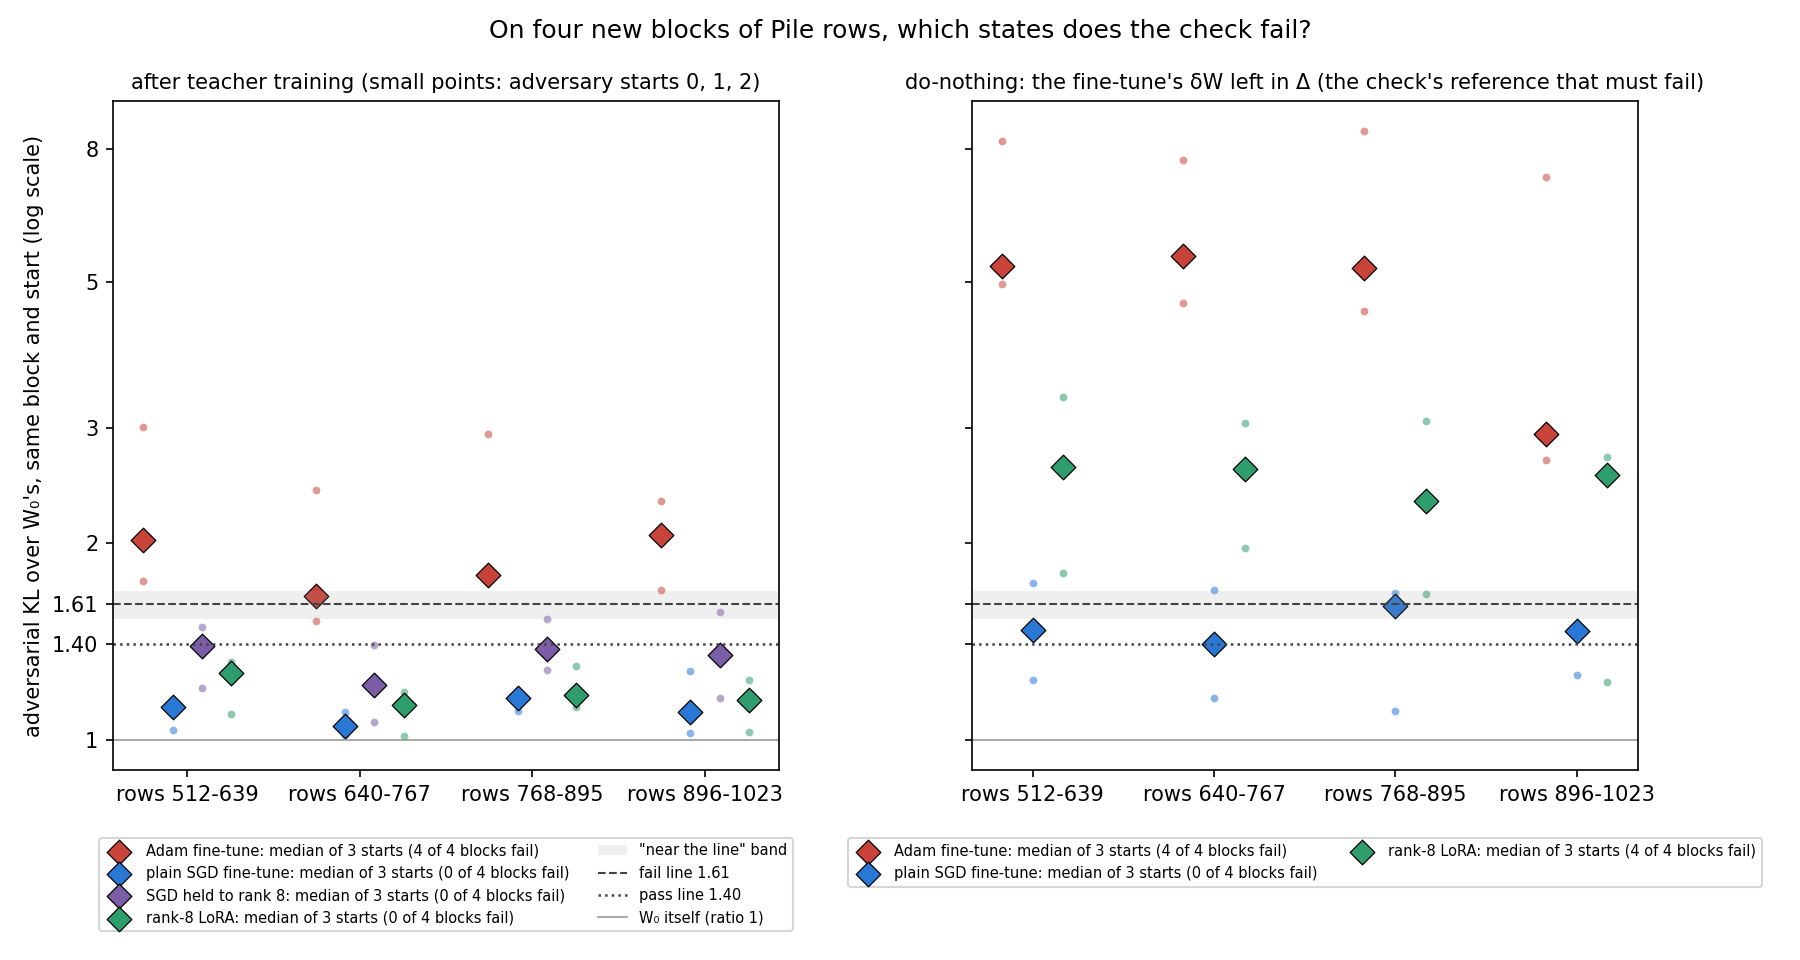

In [2]:
display(Image(filename=str(EXP / "figures" / "blocks.png")))

**Reading it.** Adam fails, the LoRA passes, and the SGD states pass a check that could not have failed them. On the
left, the red Adam medians sit above the fail line on all four blocks and the green LoRA medians under the pass line.
Both SGD states, blue and purple, sit under the pass line on all four. On the right, the Adam and LoRA do-nothings fail
every block by a wide margin, so for them the check has power on these rows. The plain SGD do-nothing, blue, never
reaches the fail line: its medians read 1.40 to 1.60. The check cannot fail plain SGD's whole update even left in Δ, so
the SGD passes on the left carry almost no weight.

Two medians sit near the line, within the band where rounding and the card can move a reading. Adam's on rows 640-767
reads 1.66, and one of its three starts falls between the lines. The plain SGD do-nothing's on rows 768-895 reads 1.60.
The spread between starts comes from the states, not W₀: W₀'s own KL stayed between 0.61 and 0.71 on every block.

In [3]:
names = {"tt_adam": "Adam, teacher-trained", "tt_sgd": "plain SGD, teacher-trained",
         "tt_sgd_r8": "SGD rank 8, teacher-trained", "tt_lora": "LoRA, teacher-trained",
         "nothing_adam": "Adam, do-nothing", "nothing_sgd": "plain SGD, do-nothing", "nothing_lora": "LoRA, do-nothing"}
rows = ["| state | median per block, rows 512 / 640 / 768 / 896 | blocks failed |", "|---|---|---|"]
for key, name in names.items():
    st = S["b"][key]
    med = " / ".join(f"{st['median'][b]:.2f}" for b in ("512", "640", "768", "896"))
    rows.append(f"| {name} | {med} | {st['fails']} of 4 |")
display(Markdown("\n".join(rows)))

| state | median per block, rows 512 / 640 / 768 / 896 | blocks failed |
|---|---|---|
| Adam, teacher-trained | 2.02 / 1.66 / 1.78 / 2.06 | 4 of 4 |
| plain SGD, teacher-trained | 1.12 / 1.05 / 1.16 / 1.10 | 0 of 4 |
| SGD rank 8, teacher-trained | 1.39 / 1.21 / 1.38 / 1.35 | 0 of 4 |
| LoRA, teacher-trained | 1.26 / 1.13 / 1.17 / 1.15 | 0 of 4 |
| Adam, do-nothing | 5.30 / 5.49 / 5.26 / 2.93 | 4 of 4 |
| plain SGD, do-nothing | 1.47 / 1.40 / 1.60 / 1.46 | 0 of 4 |
| LoRA, do-nothing | 2.61 / 2.60 / 2.31 / 2.53 | 4 of 4 |

## Does the SGD fail on rows 128-255 survive two more adversary starts?

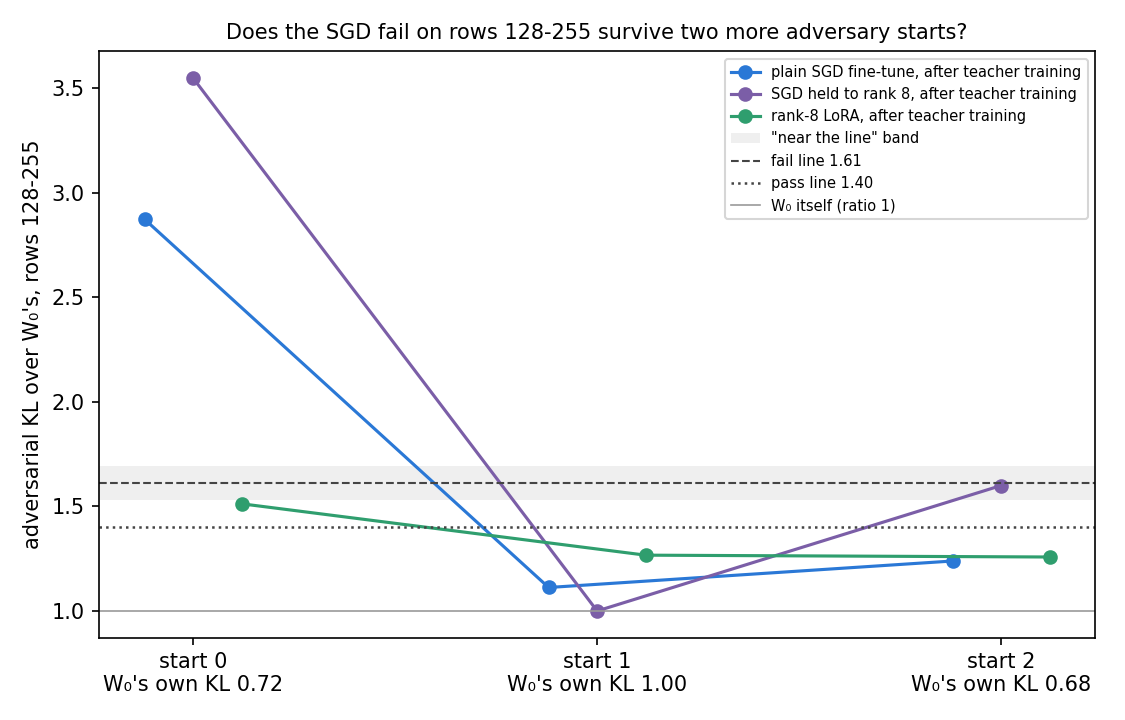

In [4]:
display(Image(filename=str(EXP / "figures" / "hard_block.png")))

**Reading it.** Not cleanly: the filed rule does not separate the start from the rows, though the numbers lean towards
the start. At start 0 both SGD states fail again, at 2.87 and 3.55. At starts 1 and 2 plain SGD passes, at 1.11 and
1.24. SGD held to rank 8 passes at start 1 but reads 1.599 at start 2, just under the fail line, so the rule reads
"mixed". The LoRA sits between the lines at start 0 and passes at the other two.

The lean, which is not a finding: the drop is in the SGD state's own KL. W₀'s KL reads 0.72, 1.00 and 0.68 over the
three starts, so W₀ is lower at start 2 than at start 0. Plain SGD's own KL fell from 2.06 to 0.85 between those two
starts. A high W₀ reading cannot explain that, and a start that happens to suit the adversary is the simpler reading.
Three starts on one block cannot say how often such a start comes up.

## Does this card reproduce the earlier SGD readings?

For plain SGD yes, for SGD held to rank 8 no. All these readings ran on the cluster's L40, while E39 read the same
saved states on an H100. On rows 0-255 at start 0, plain SGD read within 2% of its H100 reading. SGD held to rank 8 read
2.45 against 2.12, about 15% higher, past the 10% allowed. The plan reported this gate without a stop.

What it means: on this card the start-0 adversary attacks the rank-8 SGD state harder than the H100's did. Its ratios
here are still sound against W₀ read on the same card and start, which is how every ratio in this notebook is formed.
They cannot be set one-to-one against an H100 reading of that state, and the lines' fine margins were set on the H100.
The miss went in the harsh direction, so its passes on the new blocks did not come from a gentler card. Its closest
median sits 0.01 under the pass line, well inside a 15% card difference.

## What we learned

The contrast E39 drew between Adam and the LoRA now stands on eight blocks of Pile text. Adam's teacher-trained
decomposition fails every block read, the LoRA's passes every new one, and both do-nothings fail, as a working check
must. The SGD fails E39 reported rest on one block at one start, and on new blocks the SGD states pass. But the check
cannot fail plain SGD's whole update even when it sits in Δ, so this check does not say whether teacher training places
a broad SGD update. By the filed tree the line closes "Adam fails, the LoRA passes, SGD passes on most rows". The H100
follow-ups for SGD are dropped. That SGD clause is a pass on a check with no power for SGD here.

## How compelling is the evidence

- **The weakest link is the SGD half.** The SGD do-nothing fails no block, so the SGD passes are near-empty. SGD held
  to rank 8 has no do-nothing of its own; the plain one stands in.
- **Next weakest: Adam's block on rows 640-767.** Its median sits near the line, and one start more in the other
  direction could make Adam's count three of four.
- **One card, one batch order, one LoRA seed, three starts.** The lines were set from the H100's noise floor, smaller
  than the L40's. Starts move the states far more than they move W₀.
- **The check is a lower bound.** More adversary steps or starts could only find higher KLs.

## Surprises

- **The plain SGD do-nothing passes every new block.** It was expected to read 1.3 to 3.8 and maybe pass one. On most
  Pile rows the check does not see SGD's update, even whole and left in Δ.
- **Plain SGD's hard-block fail did not repeat at two more starts.** The filed lean was "the rows". The rule read
  "mixed", because the rank-8 state landed just under the fail line at one start. A narrow miss, not a reversal.
- **The rank-8 SGD card check missed**, 15% against 10%, in the harsh direction.

## What next

1. **Find a reading where the SGD do-nothing fails**, such as the lowercase task's own text or the hard block at many
   starts. Without one, SGD is named as out of this check's reach and the line closes on Adam and the LoRA.
2. **Multi-start readings for single-start verdicts near the lines.** Plain SGD's hard block moved from 2.87 to 1.11
   between starts. If other project verdicts move like that, several could flip.
3. **Two more starts on Adam's rows 640-767**, to say whether Adam fails every block.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| P1 | Hard block's SGD fail belongs to the rows | seeds 1, 2: both ≥ 1.61 per SGD state | plain 1.11, 1.24; rank 8 1.00, 1.599 | misses, "mixed" |
| P2 | Adam fails all 4 new blocks | 3-start median ≥ 1.61 | 2.02, 1.66, 1.78, 2.06 | holds; 1.66 near the line |
| P3 | Plain SGD fails ≤ 1 | same | 1.12, 1.05, 1.16, 1.10 | holds; no power |
| P4 | LoRA fails none | same | 1.26, 1.13, 1.17, 1.15 | holds |
| P5 | SGD rank 8 fails ≤ 1 | same | 1.39, 1.21, 1.38, 1.35 | holds; no power, card check missed |

## Not run

- Per-row KL on the hard block: only on a "rows" reading.
- The H100 follow-ups for SGD, a labelled SGD state and an SGD-trained LoRA: dropped by the tree.
- A do-nothing for SGD held to rank 8; any reading where the SGD do-nothing fails.
- Rows past 1023, other cards, a second LoRA seed or batch order, more starts or adversary steps.

## Provenance

MATS cluster L40, debug QoS, $0, 2026-10-29 13:21-14:39. Jobs: regen 42959, hard block 42963, new blocks
42998-43003. Job 42959 wrote its results and status "done", then hung at exit and was cancelled; its files are complete.
Results `experiments/row_blocks/results/*.json`; saved fine-tunes in `results/large/dW_{adam,sgd,lora}.pt`, listed in
`experiments/SAVED.md`. Figures from `experiments/row_blocks/plot.py`.